In [1]:
# ==========================================
# Import Required Libraries
# ==========================================

import warnings
warnings.filterwarnings("ignore")

import os
import time
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ==========================================
# Display Settings
# ==========================================

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 10)

plt.style.use("ggplot")

print("Display options configured.")

Display options configured.


In [3]:
DATA_PATH = "D:\\aiub\\Samester 10\\dataset\\final_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [4]:
print("="*60)

print("Dataset Shape")

print(df.shape)

print("="*60)

print(df.info())

Dataset Shape
(12794627, 85)
<class 'pandas.DataFrame'>
RangeIndex: 12794627 entries, 0 to 12794626
Data columns (total 85 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Unnamed: 0         int64  
 1   Flow ID            str    
 2   Src IP             str    
 3   Src Port           int64  
 4   Dst IP             str    
 5   Dst Port           int64  
 6   Protocol           int64  
 7   Timestamp          str    
 8   Flow Duration      int64  
 9   Tot Fwd Pkts       int64  
 10  Tot Bwd Pkts       int64  
 11  TotLen Fwd Pkts    float64
 12  TotLen Bwd Pkts    float64
 13  Fwd Pkt Len Max    float64
 14  Fwd Pkt Len Min    float64
 15  Fwd Pkt Len Mean   float64
 16  Fwd Pkt Len Std    float64
 17  Bwd Pkt Len Max    float64
 18  Bwd Pkt Len Min    float64
 19  Bwd Pkt Len Mean   float64
 20  Bwd Pkt Len Std    float64
 21  Flow Byts/s        float64
 22  Flow Pkts/s        float64
 23  Flow IAT Mean      float64
 24  Flow IAT Std       float64
 25

In [5]:
df.head()

,Unnamed: 0,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,Bwd Pkt Len Min,Bwd Pkt Len Mean,Bwd Pkt Len Std,Flow Byts/s,Flow Pkts/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Tot,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Tot,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Len,Bwd Header Len,Fwd Pkts/s,Bwd Pkts/s,Pkt Len Min,Pkt Len Max,Pkt Len Mean,Pkt Len Std,Pkt Len Var,FIN Flag Cnt,SYN Flag Cnt,RST Flag Cnt,PSH Flag Cnt,ACK Flag Cnt,URG Flag Cnt,CWE Flag Count,ECE Flag Cnt,Down/Up Ratio,Pkt Size Avg,Fwd Seg Size Avg,Bwd Seg Size Avg,Fwd Byts/b Avg,Fwd Pkts/b Avg,Fwd Blk Rate Avg,Bwd Byts/b Avg,Bwd Pkts/b Avg,Bwd Blk Rate Avg,Subflow Fwd Pkts,Subflow Fwd Byts,Subflow Bwd Pkts,Subflow Bwd Byts,Init Fwd Win Byts,Init Bwd Win Byts,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,624,192.168.4.118-203.73.24.75-4504-80-6,192.168.4.118,4504,203.73.24.75,80,6,12/06/2010 08:34:32 AM,3974862,29,44,86.0,59811.0,86.0,0.0,2.965517,15.969799,1460.0,0.0,1359.340909,372.027190,15068.950821,18.365417,55206.416667,195478.316654,1566821.0,167.0,3735347.0,133405.25,341775.688712,1805015.0,167.0,3974862.0,92438.651163,248174.820574,1566821.0,3997.0,0,0,0,0,768,896,7.295851,11.069567,0.0,1460.0,809.418919,728.862428,531240.438541,0,1,0,0,0,0,0,0,1.0,820.506849,2.965517,1359.340909,0,0,0,0,0,0,29,86,44,59811,-1,5840,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
1,625,192.168.4.118-203.73.24.75-4504-80-6,192.168.4.118,4504,203.73.24.75,80,6,12/06/2010 08:34:36 AM,63,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,31746.031746,63.000000,0.000000,63.0,63.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0,0,0,0,20,20,15873.015873,15873.015873,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,1.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,1,0,1,0,-1,17520,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
2,626,192.168.4.118-203.73.24.75-4505-80-6,192.168.4.118,4505,203.73.24.75,80,6,12/06/2010 08:34:36 AM,476078,2,6,86.0,3037.0,86.0,0.0,43.000000,60.811183,1460.0,0.0,506.166667,740.224403,6559.849436,16.803969,68011.142857,110862.707451,232203.0,6.0,134.0,134.00,0.000000,134.0,134.0,476078.0,95215.600000,123467.303580,232601.0,6.0,0,0,0,0,40,136,4.200992,12.602977,0.0,1460.0,347.000000,632.515217,400075.500000,0,1,0,0,0,0,0,0,3.0,390.375000,43.000000,506.166667,0,0,0,0,0,0,2,86,6,3037,-1,5840,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
3,627,192.168.4.118-203.73.24.75-4505-80-6,192.168.4.118,4505,203.73.24.75,80,6,12/06/2010 08:34:37 AM,151,2,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,19867.549669,75.500000,98.287843,145.0,6.0,145.0,145.00,0.000000,145.0,145.0,0.0,0.000000,0.000000,0.0,0.0,0,0,0,0,40,20,13245.033113,6622.516556,0.0,0.0,0.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0.0,0.000000,0.000000,0.000000,0,0,0,0,0,0,2,0,1,0,-1,17520,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos
4,628,192.168.4.118-203.73.24.75-4506-80-6,192.168.4.118,4506,203.73.24.75,80,6,12/06/2010 08:34:37 AM,472507,2,5,73.0,1050.0,73.0,0.0,36.500000,51.618795,1050.0,0.0,210.000000,469.574275,2376.684367,14.814595,78751.166667,118675.492251,232355.0,7.0,179.0,179.00,0.000000,179.0,179.0,472507.0,118126.750000,131726.857333,232875.0,7.0,0,0,0,0,40,116,4.232742,10.581854,0.0,1050.0,140.375000,368.430624,135741.125000,0,1,0,0,0,0,0,0,2.0,160.428571,36.500000,210.000000,0,0,0,0,0,0,2,73,5,1050,-1,5840,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,ddos


In [6]:
df.dtypes

Unnamed: 0      int64
Flow ID           str
Src IP            str
Src Port        int64
Dst IP            str
               ...   
Idle Mean     float64
Idle Std      float64
Idle Max      float64
Idle Min      float64
Label             str
Length: 85, dtype: object

In [7]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print(missing)

print()

print("Total Missing Values :", missing.sum())

Flow Byts/s    29713
dtype: int64

Total Missing Values : 29713


In [8]:
duplicates = df.duplicated().sum()

print("Duplicate Rows :", duplicates)

Duplicate Rows : 0


In [9]:
print(df["Label"].value_counts())

Label
ddos      6472647
Benign    6321980
Name: count, dtype: int64


In [10]:
print(df.columns)

Index(['Unnamed: 0', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port',
       'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts',
       'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag

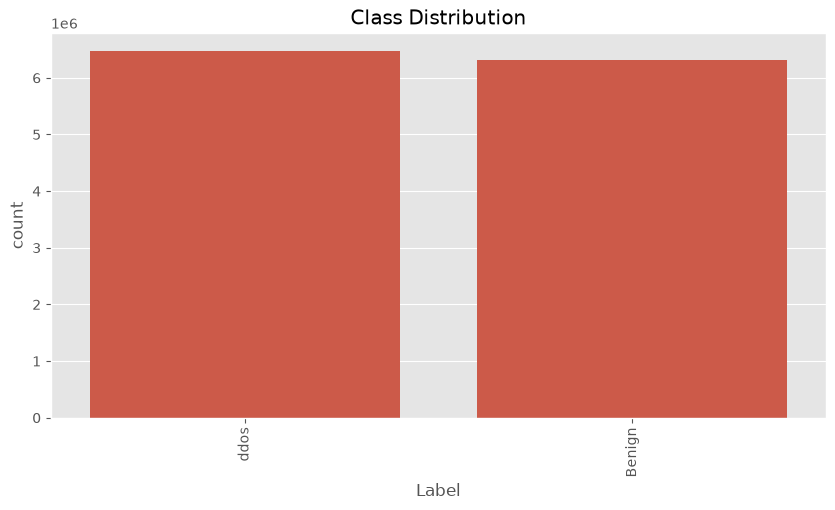

In [11]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="Label",
    order=df["Label"].value_counts().index
)

plt.xticks(rotation=90)

plt.title("Class Distribution")

plt.show()

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,12794627.0,2.662390e+06,2.169382e+06,0.0,898483.0,2040991.0,3903946.5,7.902474e+06
Src Port,12794627.0,3.707054e+04,2.521985e+04,0.0,443.0,50592.0,56215.0,6.553500e+04
Dst Port,12794627.0,1.464290e+04,2.306383e+04,0.0,80.0,80.0,38550.0,6.553500e+04
Protocol,12794627.0,7.828588e+00,4.206168e+00,0.0,6.0,6.0,6.0,1.700000e+01
Flow Duration,12794627.0,8.219593e+06,2.477327e+07,-1.0,1262.0,32065.0,4159735.5,1.200000e+08
...,...,...,...,...,...,...,...,...
Active Min,12794627.0,9.030539e+04,1.934856e+06,0.0,0.0,0.0,0.0,1.132691e+08
Idle Mean,12794627.0,3.119925e+06,1.219261e+07,0.0,0.0,0.0,0.0,1.199997e+08
Idle Std,12794627.0,1.093532e+05,1.414693e+06,0.0,0.0,0.0,0.0,7.639395e+07
Idle Max,12794627.0,3.215790e+06,1.244476e+07,0.0,0.0,0.0,0.0,1.199997e+08


In [13]:
memory = df.memory_usage(deep=True).sum() / 1024**2

print(f"Dataset Memory Usage : {memory:.2f} MB")

Dataset Memory Usage : 9356.54 MB


In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

inf_count = np.isinf(df[numeric_cols]).sum().sum()

print("Infinite Values :", inf_count)

Infinite Values : 65847


In [15]:
dataset_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.values,
    "Missing Values": df.isnull().sum().values
})

dataset_info.head()

,Column,Data Type,Missing Values
0,Unnamed: 0,int64,0
1,Flow ID,str,0
2,Src IP,str,0
3,Src Port,int64,0
4,Dst IP,str,0


In [16]:
# ==========================================
# Remove Duplicate Rows
# ==========================================

print("Dataset Shape Before:", df.shape)

df = df.drop_duplicates()

print("Dataset Shape After :", df.shape)

Dataset Shape Before: (12794627, 85)
Dataset Shape After : (12794627, 85)


In [17]:
# ==========================================
# Replace Infinite Values
# ==========================================

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced.")

Infinite values replaced.


In [18]:
# ==========================================
# Remove Missing Values
# ==========================================

print("Missing Values Before:")
print(df.isnull().sum().sum())

df.dropna(inplace=True)

print("\nMissing Values After:")
print(df.isnull().sum().sum())

Missing Values Before:
95560

Missing Values After:
0


In [19]:
# ==========================================
# Data Types
# ==========================================

df.dtypes

Unnamed: 0      int64
Flow ID           str
Src IP            str
Src Port        int64
Dst IP            str
               ...   
Idle Mean     float64
Idle Std      float64
Idle Max      float64
Idle Min      float64
Label             str
Length: 85, dtype: object

In [20]:
# ==========================================
# Memory Optimization
# ==========================================

numeric_cols = df.select_dtypes(include=['float64']).columns

df[numeric_cols] = df[numeric_cols].astype('float32')

print("Float64 converted to Float32.")

Float64 converted to Float32.


In [21]:
print(df.columns)

Index(['Unnamed: 0', 'Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port',
       'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts',
       'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag

In [22]:
# Remove accidental index column

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print("After removing Unnamed: 0:")
print(df.shape)
print(df.columns[:10])

After removing Unnamed: 0:
(12746847, 84)
Index(['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol',
       'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts'],
      dtype='str')


In [23]:
# ==========================================
# Label Encoding
# ==========================================

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Label"] = encoder.fit_transform(df["Label"])

print("Label Encoding Completed.")

Label Encoding Completed.


In [24]:
print(encoder.classes_)

['Benign' 'ddos']


In [25]:
# ==========================================
# Feature Matrix & Target
# ==========================================

X = df.drop("Label", axis=1)

y = df["Label"]

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Shape : (12746847, 83)
Target Shape  : (12746847,)


In [26]:
# ==========================================
# Create Development Dataset
# ==========================================

sample_size = 500000

df = df.sample(
    n=sample_size,
    random_state=42
).reset_index(drop=True)

print(df.shape)

(500000, 84)


In [27]:
X = df.drop("Label", axis=1)
y = df["Label"]

In [28]:
X = X.drop(columns=[
    "Flow ID",
    "Src IP",
    "Dst IP",
    "Timestamp"
])

In [29]:
int_cols = X.select_dtypes(include=["int64"]).columns

X[int_cols] = X[int_cols].astype("int32")

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(400000, 79)
(100000, 79)


In [32]:
# ==========================================
# Create Feature Selection Sample
# ==========================================

sample_size = 100000

X_fs = X_train.sample(
    n=sample_size,
    random_state=42
)

y_fs = y_train.loc[X_fs.index]

print("Feature Selection Sample:", X_fs.shape)

Feature Selection Sample: (100000, 79)


In [33]:
from xgboost import XGBClassifier

xgb_fs = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_fs.fit(X_fs, y_fs)

print("Feature Selection Model Trained Successfully!")

Feature Selection Model Trained Successfully!


In [34]:
importance = pd.DataFrame({
    "Feature": X_fs.columns,
    "Importance": xgb_fs.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.reset_index(drop=True, inplace=True)

importance.head(20)

,Feature,Importance
0,Fwd Seg Size Min,0.299724
1,Fwd PSH Flags,0.135999
2,PSH Flag Cnt,0.072593
3,Fwd Header Len,0.069260
4,Fwd Act Data Pkts,0.042735
...,...,...
15,Fwd IAT Min,0.013257
16,Init Bwd Win Byts,0.012480
17,Flow IAT Max,0.012357
18,Bwd Pkts/s,0.010549


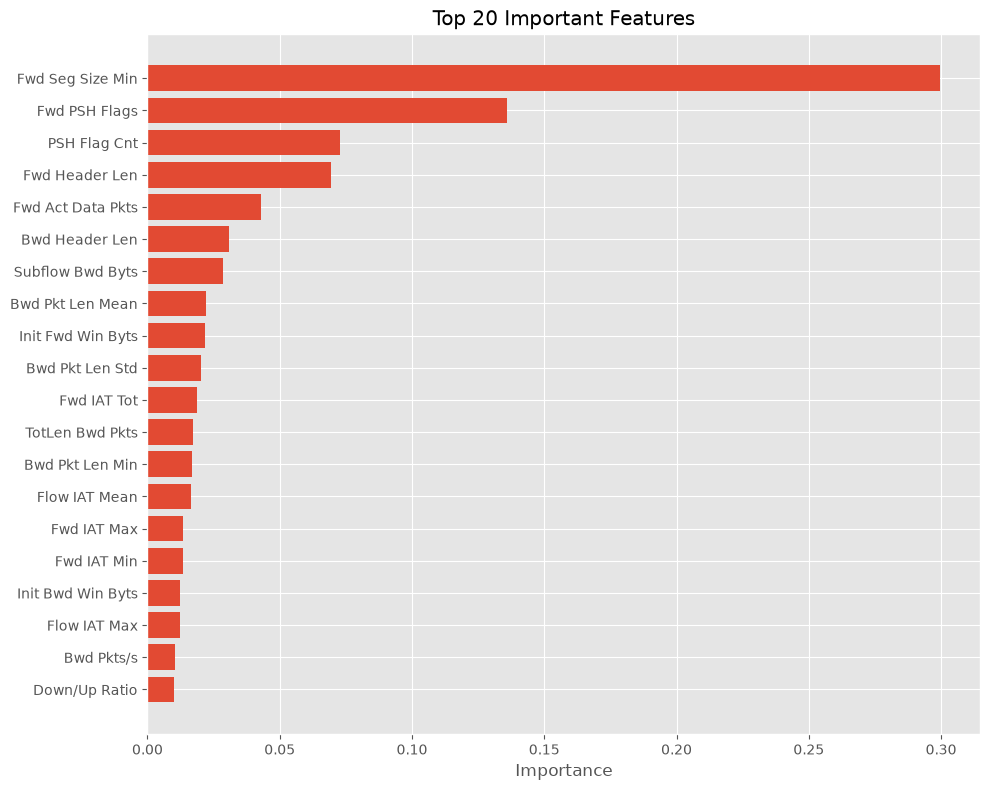

In [35]:
plt.figure(figsize=(10,8))

top20 = importance.head(20)

plt.barh(
    top20["Feature"],
    top20["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Important Features")

plt.xlabel("Importance")

plt.tight_layout()

plt.show()

In [36]:
top20_features = importance.head(20)["Feature"].tolist()
top30_features = importance.head(30)["Feature"].tolist()
top40_features = importance.head(40)["Feature"].tolist()

print("Top20:", len(top20_features))
print("Top30:", len(top30_features))
print("Top40:", len(top40_features))

Top20: 20
Top30: 30
Top40: 40


In [38]:
from xgboost import XGBClassifier
import time

xgb_all = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

start = time.time()

xgb_all.fit(X_train, y_train)

end = time.time()

print("XGBoost (All Features) Training Complete")
print("Training time:", end-start, "seconds")

XGBoost (All Features) Training Complete
Training time: 3.7765774726867676 seconds


In [39]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_all = xgb_all.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_all)
precision = precision_score(y_test, y_pred_all, average='weighted')
recall = recall_score(y_test, y_pred_all, average='weighted')
f1 = f1_score(y_test, y_pred_all, average='weighted')

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.99987
Precision: 0.9998700094693972
Recall   : 0.99987
F1 Score : 0.9998699998336876


In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_all))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     49090
           1       1.00      1.00      1.00     50910

    accuracy                           1.00    100000
   macro avg       1.00      1.00      1.00    100000
weighted avg       1.00      1.00      1.00    100000



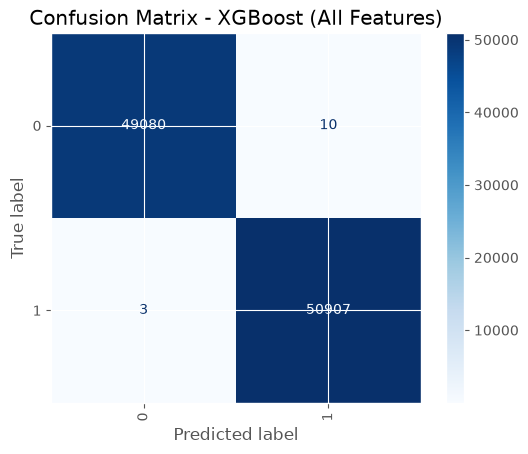

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_all,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("Confusion Matrix - XGBoost (All Features)")
plt.show()

In [42]:
X_train_top20 = X_train[top20_features]
X_test_top20 = X_test[top20_features]

X_train_top30 = X_train[top30_features]
X_test_top30 = X_test[top30_features]

X_train_top40 = X_train[top40_features]
X_test_top40 = X_test[top40_features]

In [43]:
%whos

Variable                 Type             Data/Info
---------------------------------------------------
ConfusionMatrixDisplay   type             <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_PATH                str              D:\aiub\Samester 10\dataset\final_dataset.csv
LabelEncoder             type             <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
StandardScaler           type             <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                        DataFrame        Shape: (500000, 79)
XGBClassifier            type             <class 'xgboost.sklearn.XGBClassifier'>
X_fs                     DataFrame        Shape: (100000, 79)
X_test                   DataFrame        Shape: (100000, 79)
X_test_top20             DataFrame        Shape: (100000, 20)
X_test_top30             DataFrame        Shape: (100000, 30)
X_test_top40             DataFrame        Shape: (100000, 40)
X_train                  DataFrame        Shape: (400000, 79

In [44]:
%whos XGBClassifier
%whos xgb_top20

Variable   Type             Data/Info
-------------------------------------
xgb_all    XGBClassifier    XGBClassifier(base_score=<...>_parallel_tree=None, ...)
xgb_fs     XGBClassifier    XGBClassifier(base_score=<...>_parallel_tree=None, ...)
No variables match your requested type.


In [45]:
from xgboost import XGBClassifier

xgb_top20 = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_top20.fit(X_train_top20, y_train)

print("Training Complete")

Training Complete


In [46]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

def evaluate_xgboost(X_train, X_test, y_train, y_test, model_name):

    model = XGBClassifier(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted"),
        "Recall": recall_score(y_test, pred, average="weighted"),
        "F1": f1_score(y_test, pred, average="weighted")
    }

In [ ]:
results = []

results.append(evaluate_xgboost(X_train, X_test, y_train, y_test, "All Features"))
results.append(evaluate_xgboost(X_train_top20, X_test_top20, y_train, y_test, "Top 20"))
results.append(evaluate_xgboost(X_train_top30, X_test_top30, y_train, y_test, "Top 30"))
results.append(evaluate_xgboost(X_train_top40, X_test_top40, y_train, y_test, "Top 40"))

results_df = pd.DataFrame(results)
print(results_df)

          Model  Accuracy  Precision   Recall       F1
0  All Features   0.99987    0.99987  0.99987  0.99987
1        Top 20   0.99963    0.99963  0.99963  0.99963
2        Top 30   0.99973    0.99973  0.99973  0.99973
3        Top 40   0.99984    0.99984  0.99984  0.99984


In [48]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [49]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
Available GPUs: []


In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_top20)
X_test_scaled = scaler.transform(X_test_top20)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(400000, 20)
(100000, 20)


In [51]:
import numpy as np

X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_test_lstm = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print(X_train_lstm.shape)
print(X_test_lstm.shape)

(400000, 20, 1)
(100000, 20, 1)


In [52]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

num_classes = len(np.unique(y_train))

model = Sequential([
    LSTM(64, input_shape=(20, 1)),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,186 (82.76 KB)

 Trainable params: 21,186 (82.76 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
history = model.fit(
    X_train_lstm,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=512,
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9280 - loss: 0.2169 - val_accuracy: 0.9638 - val_loss: 0.1235
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9678 - loss: 0.1149 - val_accuracy: 0.9758 - val_loss: 0.0842
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9757 - loss: 0.0869 - val_accuracy: 0.9772 - val_loss: 0.0766
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9802 - loss: 0.0684 - val_accuracy: 0.9846 - val_loss: 0.0500
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9841 - loss: 0.0536 - val_accuracy: 0.9857 - val_loss: 0.0463
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9845 - loss: 0.0501 - val_accuracy: 0.9861 - val_loss: 0.0435
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9852 - loss: 0.0462 - val_accuracy: 0.9843 - val_loss: 0.0445
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9855 - loss: 0.0456 - 

In [72]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# LSTM prediction
y_pred_prob = model.predict(X_test_lstm)

# Convert probabilities to labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Calculate metrics
lstm_accuracy = accuracy_score(y_test, y_pred)

lstm_precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

lstm_recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

lstm_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)


print("LSTM Accuracy :", lstm_accuracy)
print("LSTM Precision:", lstm_precision)
print("LSTM Recall   :", lstm_recall)
print("LSTM F1 Score :", lstm_f1)

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
LSTM Accuracy : 0.98875
LSTM Precision: 0.9887970565748692
LSTM Recall   : 0.98875
LSTM F1 Score : 0.9887486911212766


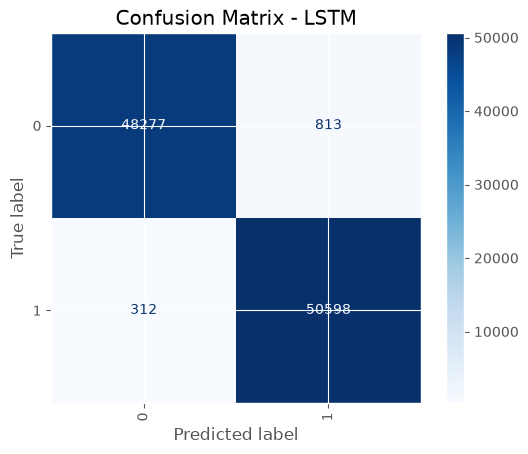

In [55]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("Confusion Matrix - LSTM")
plt.show()

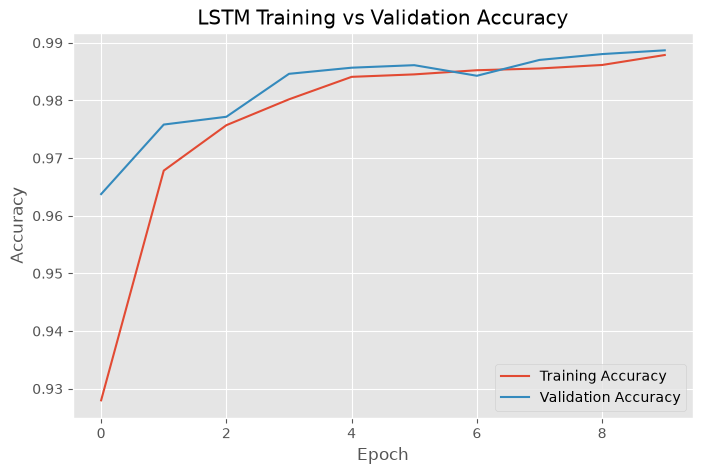

In [56]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training vs Validation Accuracy")
plt.legend()

plt.show()

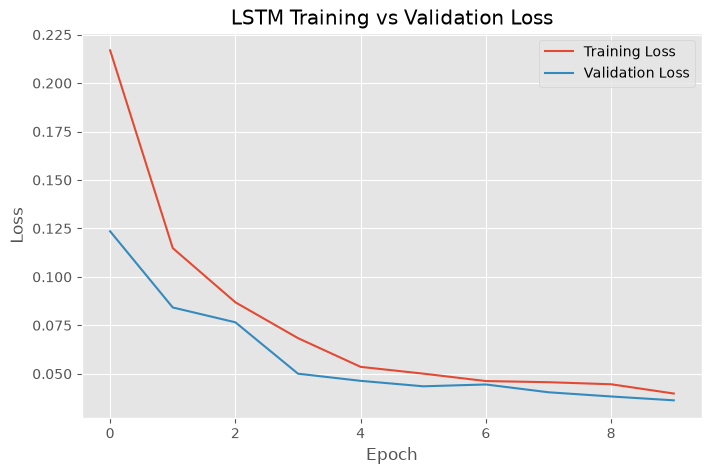

In [57]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()

plt.show()

In [58]:
import os
print(os.getcwd())

d:\aiub\Samester 10\DDoS Paper


In [59]:
%whos

Variable                 Type              Data/Info
----------------------------------------------------
ConfusionMatrixDisplay   type              <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_PATH                str               D:\aiub\Samester 10\dataset\final_dataset.csv
Dense                    type              <class 'keras.src.layers.core.dense.Dense'>
Dropout                  type              <class 'keras.src.layers.<...>ization.dropout.Dropout'>
LSTM                     type              <class 'keras.src.layers.rnn.lstm.LSTM'>
LabelEncoder             type              <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
Sequential               type              <class 'keras.src.models.sequential.Sequential'>
StandardScaler           type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                        DataFrame         Shape: (500000, 79)
XGBClassifier            type              <class 'xgboost.sklearn.XGBClassifier'>


In [60]:
from xgboost import XGBClassifier

xgb_all = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_all.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [61]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(xgb_all, "models/xgb_all.pkl")

print("Saved!")

Saved!


In [62]:
%whos

Variable                 Type              Data/Info
----------------------------------------------------
ConfusionMatrixDisplay   type              <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_PATH                str               D:\aiub\Samester 10\dataset\final_dataset.csv
Dense                    type              <class 'keras.src.layers.core.dense.Dense'>
Dropout                  type              <class 'keras.src.layers.<...>ization.dropout.Dropout'>
LSTM                     type              <class 'keras.src.layers.rnn.lstm.LSTM'>
LabelEncoder             type              <class 'sklearn.preproces<...>ing._label.LabelEncoder'>
Sequential               type              <class 'keras.src.models.sequential.Sequential'>
StandardScaler           type              <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                        DataFrame         Shape: (500000, 79)
XGBClassifier            type              <class 'xgboost.sklearn.XGBClassifier'>


In [63]:
import shap

print(shap.__version__)

0.51.0


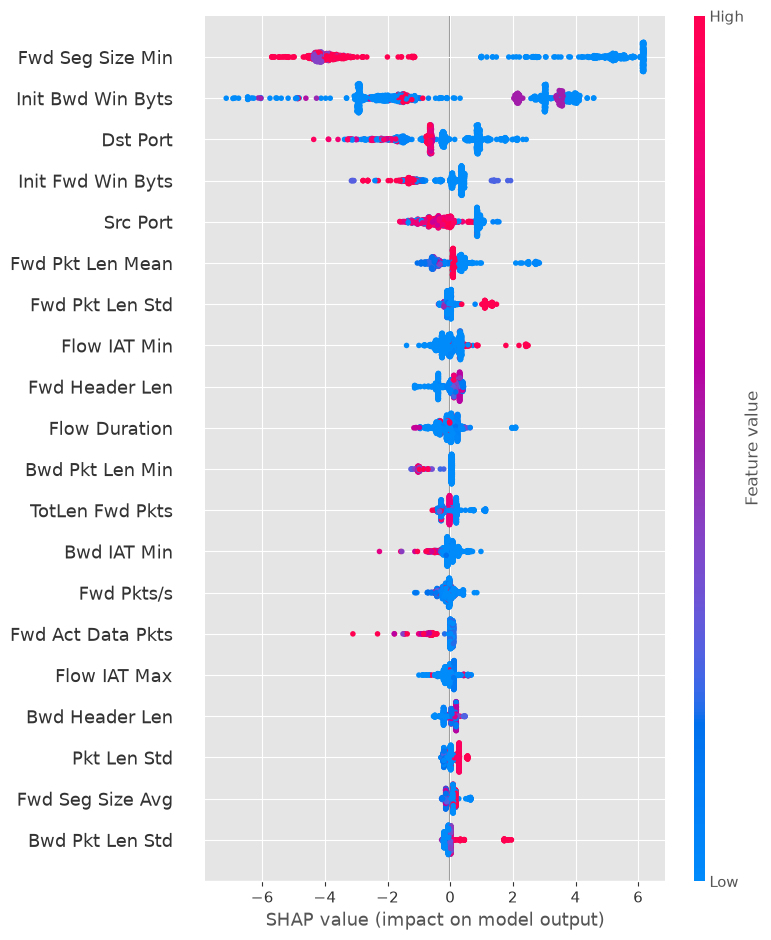

In [64]:
import shap

explainer = shap.TreeExplainer(xgb_all)

shap_values = explainer.shap_values(X_test.iloc[:1000])

shap.summary_plot(
    shap_values,
    X_test.iloc[:1000]
)

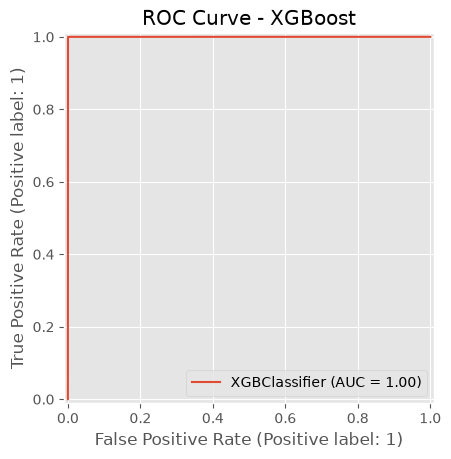

In [65]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    xgb_all,
    X_test,
    y_test
)

plt.title("ROC Curve - XGBoost")
plt.show()

In [66]:
importance.to_csv("feature_importance.csv", index=False)

print(importance.head(20))

              Feature  Importance
0    Fwd Seg Size Min    0.299724
1       Fwd PSH Flags    0.135999
2        PSH Flag Cnt    0.072593
3      Fwd Header Len    0.069260
4   Fwd Act Data Pkts    0.042735
..                ...         ...
15        Fwd IAT Min    0.013257
16  Init Bwd Win Byts    0.012480
17       Flow IAT Max    0.012357
18         Bwd Pkts/s    0.010549
19      Down/Up Ratio    0.010185

[20 rows x 2 columns]


In [67]:
print(results_df)

          Model  Accuracy  Precision   Recall       F1
0  All Features   0.99987    0.99987  0.99987  0.99987
1        Top 20   0.99963    0.99963  0.99963  0.99963
2        Top 30   0.99973    0.99973  0.99973  0.99973
3        Top 40   0.99984    0.99984  0.99984  0.99984


In [68]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "XGBoost (All Features)",
        "XGBoost (Top 20 Features)",
        "XGBoost (Top 30 Features)",
        "XGBoost (Top 40 Features)",
        "LSTM (Top 20 Features)"
    ],
    "Accuracy": [
        results_df.iloc[0]["Accuracy"],
        results_df.iloc[1]["Accuracy"],
        results_df.iloc[2]["Accuracy"],
        results_df.iloc[3]["Accuracy"],
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        results_df.iloc[0]["Precision"],
        results_df.iloc[1]["Precision"],
        results_df.iloc[2]["Precision"],
        results_df.iloc[3]["Precision"],
        precision_score(y_test, y_pred, average="weighted")
    ],
    "Recall": [
        results_df.iloc[0]["Recall"],
        results_df.iloc[1]["Recall"],
        results_df.iloc[2]["Recall"],
        results_df.iloc[3]["Recall"],
        recall_score(y_test, y_pred, average="weighted")
    ],
    "F1 Score": [
        results_df.iloc[0]["F1"],
        results_df.iloc[1]["F1"],
        results_df.iloc[2]["F1"],
        results_df.iloc[3]["F1"],
        f1_score(y_test, y_pred, average="weighted")
    ]
})

print(comparison)

                       Model  Accuracy  Precision   Recall  F1 Score
0     XGBoost (All Features)   0.99987   0.999870  0.99987  0.999870
1  XGBoost (Top 20 Features)   0.99963   0.999630  0.99963  0.999630
2  XGBoost (Top 30 Features)   0.99973   0.999730  0.99973  0.999730
3  XGBoost (Top 40 Features)   0.99984   0.999840  0.99984  0.999840
4     LSTM (Top 20 Features)   0.98875   0.988797  0.98875  0.988749


In [69]:
comparison.to_csv("model_comparison.csv", index=False)

print("Comparison table saved successfully!")

Comparison table saved successfully!
